In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
data = {
    "Annual_Income": [15, 16, 17, 18, 20,  # Low income
                      40, 42, 45, 48, 50,  # Medium income
                      80, 85, 90, 95, 100], # High income

    "Spending_Score": [20, 25, 18, 22, 30,
                       75, 80, 70, 85, 78,
                       15, 20, 10, 25, 18]
}

df = pd.DataFrame(data)

print(df)


X = df[["Annual_Income", "Spending_Score"]]


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

    Annual_Income  Spending_Score
0              15              20
1              16              25
2              17              18
3              18              22
4              20              30
5              40              75
6              42              80
7              45              70
8              48              85
9              50              78
10             80              15
11             85              20
12             90              10
13             95              25
14            100              18


C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\PMLS\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs

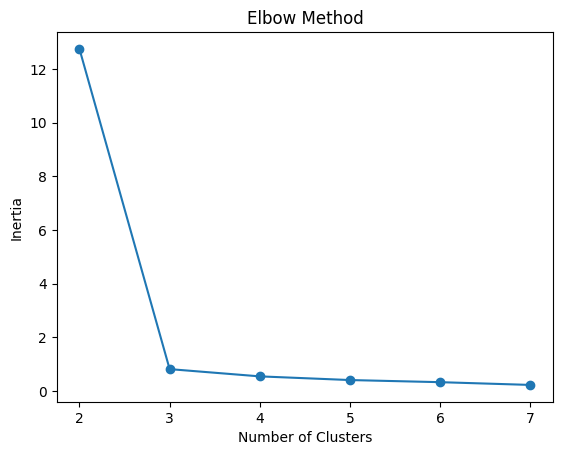

In [3]:
# Find the best number of clusters using elbow method
inertia = []

for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(2, 8), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [4]:
# Applying K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nCustomer Segments:")
print(df)



Customer Segments:
    Annual_Income  Spending_Score  Cluster
0              15              20        2
1              16              25        2
2              17              18        2
3              18              22        2
4              20              30        2
5              40              75        0
6              42              80        0
7              45              70        0
8              48              85        0
9              50              78        0
10             80              15        1
11             85              20        1
12             90              10        1
13             95              25        1
14            100              18        1


In [5]:

score = silhouette_score(X_scaled, df["Cluster"])
print("\nSilhouette Score:", score)



Silhouette Score: 0.8510099099874397


In [6]:
# PCA to reduce features to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\nExplained Variance Ratio:",
      pca.explained_variance_ratio_)


Explained Variance Ratio: [0.60040383 0.39959617]


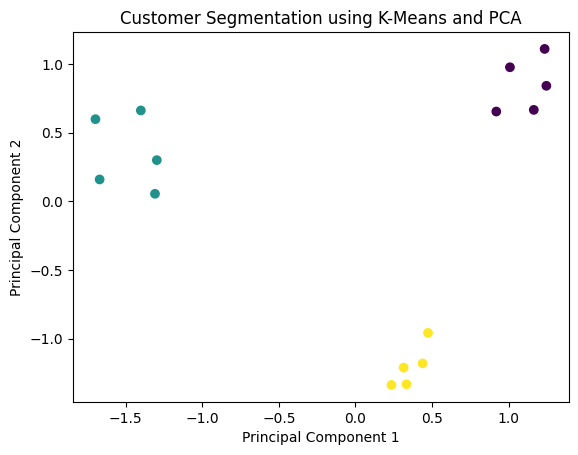

In [7]:
# Visualize customer clusters
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation using K-Means and PCA")
plt.show()